# 09_fault_diagnosis
실제 학습/평가 결과를 읽는 실행 가능한 분석 노트북. 원자료 학습 재실행은 run_phase2.ps1 참조.


In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
if not (ROOT/'reports').exists(): ROOT=ROOT.parent
display(Markdown((ROOT/'reports/markdown/09_fault_diagnosis_and_delay.md').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT/'reports/tables/phase2/primary_dense_per_fault.csv').head(70))


# 고장별 진단과 탐지 지연

| fault | post_samples | detection_recall | conditional_diagnosis_recall | end_to_end_recall |
| --- | --- | --- | --- | --- |
| 1 | 400000 | 0.9907 | 0.9606 | 0.9606 |
| 2 | 400000 | 0.9811 | 0.9615 | 0.9615 |
| 3 | 400000 | 0.6444 | 0.9605 | 0.6430 |
| 4 | 400000 | 0.9986 | 0.9750 | 0.9750 |
| 5 | 400000 | 0.9968 | 0.9648 | 0.9648 |
| 6 | 400000 | 0.9976 | 0.9820 | 0.9820 |
| 7 | 400000 | 0.9966 | 0.9882 | 0.9882 |
| 8 | 400000 | 0.9722 | 0.9578 | 0.9575 |
| 9 | 400000 | 0.1649 | 0.2432 | 0.0004 |
| 10 | 400000 | 0.9267 | 0.9357 | 0.9221 |
| 11 | 400000 | 0.9870 | 0.9840 | 0.9830 |
| 12 | 400000 | 0.9891 | 0.9593 | 0.9593 |
| 13 | 400000 | 0.9550 | 0.9285 | 0.9283 |
| 14 | 400000 | 0.9943 | 0.9876 | 0.9876 |
| 15 | 400000 | 0.0140 | 0.7239 | 0.0000 |
| 16 | 400000 | 0.9479 | 0.9516 | 0.9383 |
| 17 | 400000 | 0.9630 | 0.9579 | 0.9579 |
| 18 | 400000 | 0.9416 | 0.9286 | 0.9278 |
| 19 | 400000 | 0.9743 | 0.9829 | 0.9733 |
| 20 | 400000 | 0.9122 | 0.9388 | 0.9107 |

| system | fault | runs | detected_runs | median_delay_minutes | mean_delay_minutes | p90_delay_minutes | run_detection_rate | miss_rate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| dedicated_binary | 1 | 500 | 500 | 21.0000 | 21.8700 | 27.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 2 | 500 | 500 | 81.0000 | 79.8660 | 108.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 3 | 500 | 356 | 871.5000 | 937.6011 | 1930.5000 | 0.7120 | 0.2880 |
| dedicated_binary | 4 | 500 | 500 | 9.0000 | 9.0000 | 9.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 5 | 500 | 500 | 15.0000 | 14.7420 | 18.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 6 | 500 | 500 | 27.0000 | 25.6380 | 33.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 7 | 500 | 500 | 12.0000 | 10.9080 | 12.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 8 | 500 | 500 | 78.0000 | 81.3300 | 117.3000 | 1.0000 | 0.0000 |
| dedicated_binary | 9 | 500 | 314 | 1011.0000 | 1038.5064 | 2078.1000 | 0.6280 | 0.3720 |
| dedicated_binary | 10 | 500 | 500 | 111.0000 | 128.8860 | 228.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 11 | 500 | 500 | 27.0000 | 29.1240 | 45.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 12 | 500 | 500 | 30.0000 | 33.0960 | 48.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 13 | 500 | 500 | 135.0000 | 142.4340 | 222.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 14 | 500 | 500 | 12.0000 | 11.5200 | 15.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 15 | 500 | 360 | 802.5000 | 918.0083 | 1934.4000 | 0.7200 | 0.2800 |
| dedicated_binary | 16 | 500 | 500 | 75.0000 | 85.3080 | 141.3000 | 1.0000 | 0.0000 |
| dedicated_binary | 17 | 500 | 500 | 102.0000 | 110.3160 | 186.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 18 | 500 | 500 | 144.0000 | 157.0260 | 264.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 19 | 500 | 500 | 27.0000 | 27.7560 | 45.0000 | 1.0000 | 0.0000 |
| dedicated_binary | 20 | 500 | 500 | 132.0000 | 133.2240 | 204.0000 | 1.0000 | 0.0000 |
| joint_primary | 1 | 500 | 500 | 33.0000 | 31.3680 | 36.0000 | 1.0000 | 0.0000 |
| joint_primary | 2 | 500 | 500 | 54.0000 | 54.3480 | 60.0000 | 1.0000 | 0.0000 |
| joint_primary | 3 | 500 | 500 | 54.0000 | 65.4900 | 123.0000 | 1.0000 | 0.0000 |
| joint_primary | 4 | 500 | 500 | 12.0000 | 12.3780 | 15.0000 | 1.0000 | 0.0000 |
| joint_primary | 5 | 500 | 500 | 18.0000 | 16.6980 | 21.0000 | 1.0000 | 0.0000 |
| joint_primary | 6 | 500 | 500 | 15.0000 | 14.6940 | 15.0000 | 1.0000 | 0.0000 |
| joint_primary | 7 | 500 | 500 | 18.0000 | 17.1360 | 18.0000 | 1.0000 | 0.0000 |
| joint_primary | 8 | 500 | 500 | 69.0000 | 73.7400 | 108.0000 | 1.0000 | 0.0000 |
| joint_primary | 9 | 500 | 500 | 187.5000 | 254.8140 | 543.0000 | 1.0000 | 0.0000 |
| joint_primary | 10 | 500 | 500 | 87.0000 | 93.3780 | 141.0000 | 1.0000 | 0.0000 |
| joint_primary | 11 | 500 | 500 | 33.0000 | 35.4420 | 54.0000 | 1.0000 | 0.0000 |
| joint_primary | 12 | 500 | 500 | 33.0000 | 35.1240 | 51.0000 | 1.0000 | 0.0000 |
| joint_primary | 13 | 500 | 500 | 108.0000 | 112.6140 | 174.0000 | 1.0000 | 0.0000 |
| joint_primary | 14 | 500 | 500 | 27.0000 | 26.1060 | 33.0000 | 1.0000 | 0.0000 |
| joint_primary | 15 | 500 | 351 | 858.0000 | 962.8376 | 2007.0000 | 0.7020 | 0.2980 |
| joint_primary | 16 | 500 | 500 | 60.0000 | 62.1000 | 90.0000 | 1.0000 | 0.0000 |
| joint_primary | 17 | 500 | 500 | 90.0000 | 96.2220 | 171.0000 | 1.0000 | 0.0000 |
| joint_primary | 18 | 500 | 500 | 135.0000 | 144.1080 | 243.0000 | 1.0000 | 0.0000 |
| joint_primary | 19 | 500 | 500 | 42.0000 | 42.4680 | 63.0000 | 1.0000 | 0.0000 |
| joint_primary | 20 | 500 | 500 | 135.0000 | 137.5140 | 207.0000 | 1.0000 | 0.0000 |

![고장 성능과 지연](../figures/phase2/fault_performance_delay.png)

주 모델 전체 고장 실행의3연속 경보 검출률은 98.51%, 검출된 실행의 지연 중앙값은 48.0분이다. 미검출 실행의 지연을0으로 채우지 않았고 평균/중앙값 계산에서 제외했다. 고장마다 분포가 다르므로 전체 중앙값만으로 조기 검출을 판단하면 안 된다.

Fault별 Recall은 모든800개 post-injection 샘플을 포함한다. 주입 직후 실제 반응 전 구간을 임의로 제거하지 않았다. 진단 오류와 미탐지를 구분한다. threshold는 Test에서 변경하지 않았다. 알려진 까다로운 고장을 제거한 점수도 주 결과로 사용하지 않았다.


## 출처 및 재현

- 데이터: Harvard Dataverse V1.0, https://doi.org/10.7910/DVN/6C3JR1 . RData 4개의 공식 MD5 일치를 Phase 1에서 확인했다.
- 공정·공개 고장 참조: https://github.com/Blound04/tennessee-eastman-dataset . Dataset A는 학습에 사용하지 않았다. A의 물리 정의를 B 구현과 완전히 동일하다고 가정하지 않았다.
- API: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/gpu/index.html), [PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.rnn.LSTM.html).
- 실제 설정: configs/phase2.json, 모델 선택 기록: models/phase2/selection_lock.json. 표·그림은 reports/tables/phase2, reports/figures/phase2에 있다.


,fault,post_samples,detection_recall,conditional_diagnosis_recall,end_to_end_recall
0,1,400000,0.990690,0.960642,0.960642
1,2,400000,0.981110,0.961450,0.961450
2,3,400000,0.644355,0.960527,0.642955
3,4,400000,0.998592,0.975047,0.975047
4,5,400000,0.996792,0.964845,0.964845
5,6,400000,0.997635,0.981958,0.981958
6,7,400000,0.996610,0.988155,0.988155
7,8,400000,0.972180,0.957800,0.957498
8,9,400000,0.164865,0.243243,0.000403
9,10,400000,0.926723,0.935693,0.922053


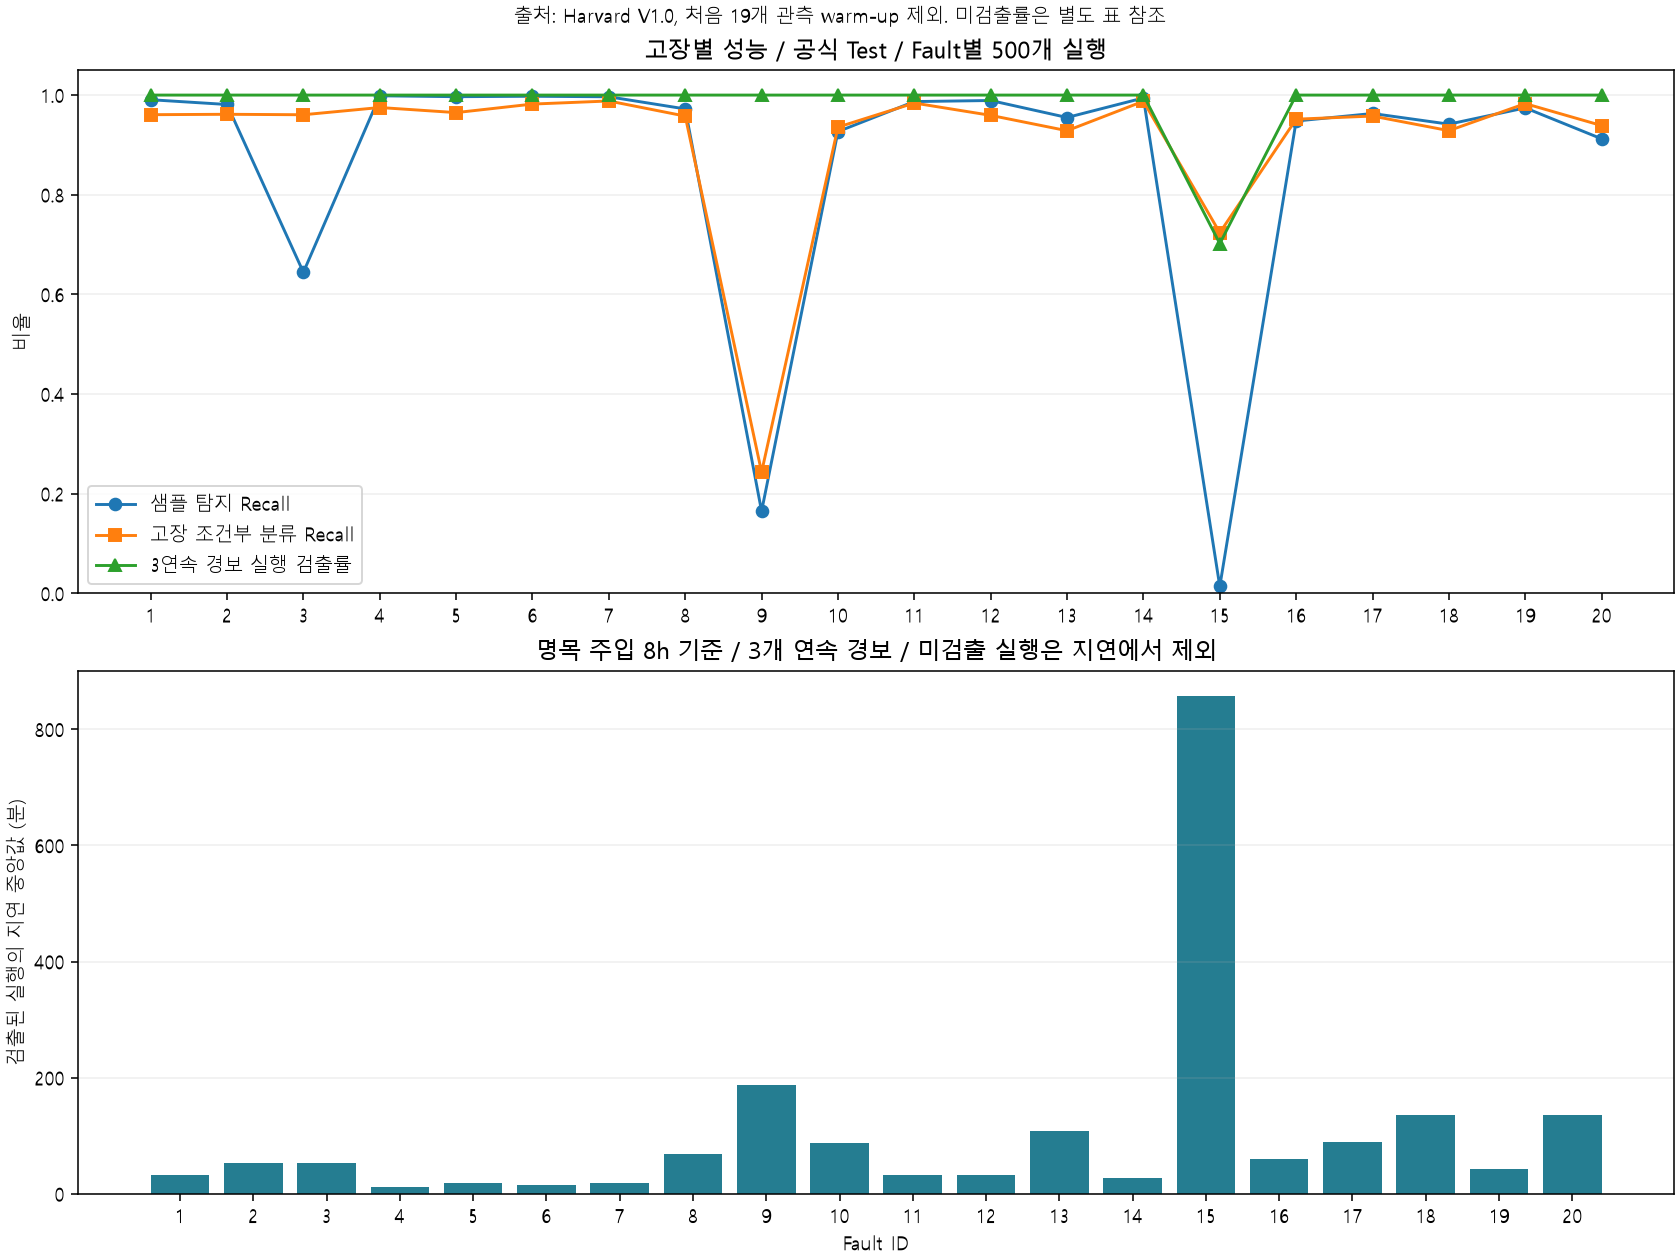

In [2]:
display(Image(filename=str(ROOT/'reports/figures/phase2/fault_performance_delay.png')))
